In [1]:
from pathlib import Path
import hashlib

# Locate label files in the attached dataset..
input_dir = Path("/kaggle/input")
train_files = list(input_dir.rglob("train.txt"))

if len(train_files) != 1:
    raise RuntimeError(f"Expected exactly one train.txt, found {len(train_files)}: "f"{train_files}")

dataset_dir = train_files[0].parent
print("Dataset folder:", dataset_dir)

for split, expected in [("train", 29986), ("test", 400)]:
    label_path = dataset_dir / f"{split}.txt"

    if not label_path.is_file():
        raise FileNotFoundError(label_path)

    content = label_path.read_bytes()
    lines = [line for line in content.decode("utf-8-sig").splitlines() if line.strip()]

    print(f"\n{split.upper()}")
    print("Non-empty label rows:", len(lines))
    print("Expected rows:", expected)
    print("Count matches:", len(lines) == expected)
    print("SHA-256:", hashlib.sha256(content).hexdigest())
    print("First 3 rows:")
    for line in lines[:3]:
        print(line)

Dataset folder: /kaggle/input/covidx-cxr2

TRAIN
Non-empty label rows: 29986
Expected rows: 29986
Count matches: True
SHA-256: 52af9a4fdc769396bc5ce530872cf0d51bce8fd7e25579b333007d4ebee6a6ba
First 3 rows:
5 ARDSSevere.png negative cohen
25 acute-respiratory-distress-syndrome-ards-1.jpg negative cohen
26 acute-respiratory-distress-syndrome-ards.jpg negative cohen

TEST
Non-empty label rows: 400
Expected rows: 400
Count matches: True
SHA-256: 7c92ae0bef49652005e1541a1f2b774e313be4431a891cb0aa5539d37ca2a71e
First 3 rows:
419639-003251 MIDRC-RICORD-1C-419639-003251-46647-0.png positive ricord
419639-001464 MIDRC-RICORD-1C-419639-001464-39871-0.png positive ricord
419639-000918 MIDRC-RICORD-1C-419639-000918-78965-0.png positive ricord


In [2]:
import pandas as pd

columns = ["patient_id", "filename", "label", "source"]
label_tables = {}

for split in ["train", "test"]:
    path = dataset_dir / f"{split}.txt"

    # Validate that each non-empty label row contains four fields.
    rows = [line.split() for line in path.read_text(encoding="utf-8-sig").splitlines() if line.strip()]

    bad_rows = [ row_number for row_number, row in enumerate(rows, start=1)if len(row) != 4]

    if bad_rows:raise ValueError( f"{split}: unexpected label format at non-empty rows "f"{bad_rows[:10]}")

    df = pd.DataFrame(rows, columns=columns)
    label_tables[split] = df

    image_dir = dataset_dir / split
    if not image_dir.is_dir():
        raise FileNotFoundError(image_dir)

    missing = [name for name in df["filename"]if not (image_dir / name).is_file() ]

    print(f"\n--- {split.upper()} ---")
    print("Label rows:", len(df))
    print("Unique filenames:", df["filename"].nunique())
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Repeated filename rows:", df["filename"].duplicated().sum())
    print("Rows with missing images:", len(missing))
    print("First missing filenames:", missing[:5])

    print("\nClass counts:")
    print(df["label"].value_counts().to_string())

    print("\nSource counts:")
    print(df["source"].value_counts().to_string())

train_df = label_tables["train"]
test_df = label_tables["test"]

shared_patients = (set(train_df["patient_id"]) & set(test_df["patient_id"]))
shared_filenames = (set(train_df["filename"]) & set(test_df["filename"]))

print("\n--- SPLIT CHECKS ---")
print("Shared patient ID strings:", len(shared_patients))
print("Shared filenames:", len(shared_filenames))


--- TRAIN ---
Label rows: 29986
Unique filenames: 29986
Exact duplicate rows: 0
Repeated filename rows: 0
Rows with missing images: 0
First missing filenames: []

Class counts:
label
positive    15994
negative    13992

Source counts:
source
stonybrook    13636
rsna          13588
sirm            943
ricord          896
cohen           567
bimcv           200
actmed          132
fig1             24

--- TEST ---
Label rows: 400
Unique filenames: 400
Exact duplicate rows: 0
Repeated filename rows: 0
Rows with missing images: 0
First missing filenames: []

Class counts:
label
positive    200
negative    200

Source counts:
source
ricord    200
rsna      200

--- SPLIT CHECKS ---
Shared patient ID strings: 0
Shared filenames: 0


label  negative  positive  total
split                           
train     13992     15994  29986
test        200       200    400


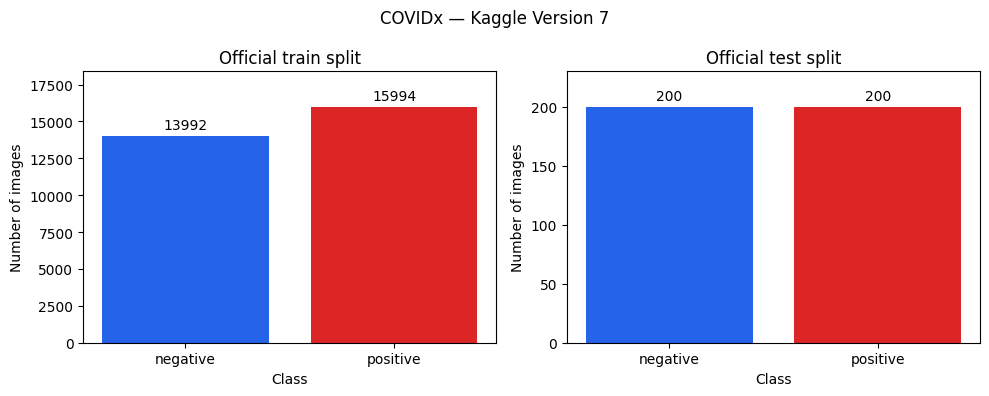


Saved outputs:
/kaggle/working/artifacts/results/dataset_summary.csv
/kaggle/working/artifacts/results/class_distribution.png


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Save generated outputs to the Kaggle working directory.
results_dir = Path("/kaggle/working/artifacts/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Count images per class in each official split.
summary = pd.DataFrame({split: df["label"].value_counts()for split, df in label_tables.items()}).T.fillna(0).astype(int)

summary = summary.reindex(columns=["negative", "positive"])
summary.index.name = "split"
summary["total"] = summary.sum(axis=1)

print(summary.to_string())

summary.to_csv(results_dir / "dataset_summary.csv")

# Plot splits separately because their sizes differ substantially.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, split in zip(axes, ["train", "test"]):
    counts = summary.loc[split, ["negative", "positive"]]

    bars = ax.bar(counts.index,counts.values,color=["#2563EB", "#DC2626"],)

    ax.bar_label(bars, padding=3)
    ax.set_title(f"Official {split} split")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of images")
    ax.set_ylim(0, counts.max() * 1.15)

fig.suptitle("COVIDx — Kaggle Version 7")
fig.tight_layout()

fig.savefig(results_dir / "class_distribution.png",dpi=150,bbox_inches="tight",)

plt.show()
plt.close(fig)

print("\nSaved outputs:")
print(results_dir / "dataset_summary.csv")
print(results_dir / "class_distribution.png")

In [4]:
from PIL import Image
import pandas as pd

image_checks = []

for split, df in label_tables.items():
    print(f"Checking {split}: {len(df)} images...")

    for number, row in enumerate(df.itertuples(index=False), start=1):
        path = dataset_dir / split / row.filename

        result = {"split": split,"filename": row.filename,"width": None,"height": None,"mode": None,"readable": False,"error": "",}

        try:
            with Image.open(path) as image:
                # Decode pixels to detect unreadable image files.
                image.load()

                result.update(width=image.width,height=image.height,mode=image.mode,readable=True,)

        except Exception as error:
            result["error"] = f"{type(error).__name__}: {error}"

        image_checks.append(result)

        if number % 5000 == 0:
            print(f"  Checked {number}/{len(df)}")

checks_df = pd.DataFrame(image_checks)

report_path = results_dir / "image_readability.csv"
checks_df.to_csv(report_path, index=False)

print("\nReadability summary:")
print(checks_df.groupby("split")["readable"].agg(total="size", readable="sum"))

bad_images = checks_df.loc[~checks_df["readable"]]

print("\nUnreadable images:", len(bad_images))
print("Report saved:", report_path)

if not bad_images.empty:
    print(bad_images[["split", "filename", "error"]].head(10).to_string(index=False))

Checking train: 29986 images...
  Checked 5000/29986
  Checked 10000/29986
  Checked 15000/29986
  Checked 20000/29986
  Checked 25000/29986
Checking test: 400 images...

Readability summary:
       total  readable
split                 
test     400       400
train  29986     29986

Unreadable images: 0
Report saved: /kaggle/working/artifacts/results/image_readability.csv


In [5]:
# Summarize image dimensions and modes without modifying source images.
readable_df = checks_df.loc[checks_df["readable"]].copy()

dimension_summary = (readable_df.groupby("split")[["width", "height"]].agg(["min", "median", "max"]))

mode_summary = pd.crosstab(readable_df["split"],readable_df["mode"],)

print("Image dimensions:")
print(dimension_summary.to_string())

print("\nImage modes:")
print(mode_summary.to_string())

dimension_summary.to_csv(results_dir / "image_dimensions_summary.csv")
mode_summary.to_csv(results_dir / "image_modes_summary.csv")

Image dimensions:
      width               height              
        min  median   max    min  median   max
split                                         
test   1024  1418.5  4240   1024  1432.5  4240
train   157  1024.0  4248    156  1024.0  4240

Image modes:
mode       L  P  RGB  RGBA
split                     
test     400  0    0     0
train  29328  3  366   289


## Image Readability and Format Summary

All 30,386 labeled images were successfully decoded:
29,986 training images and 400 test images. No unreadable
images were detected.

Image dimensions vary across the dataset. Training images
include grayscale (L), palette (P), RGB, and RGBA modes.
All test images use grayscale (L).

The initial preprocessing plan is to standardize images to
single-channel grayscale and resize with padding to 224 × 224.
The same preprocessing will be used during training and inference.
Original image files will remain unchanged.

Successful decoding does not establish clinical image quality.
Duplicate image content checks are still pending.

In [6]:
import hashlib
import pandas as pd

hash_records = []

for split, df in label_tables.items():
    print(f"Hashing {split}: {len(df)} files...")

    for number, row in enumerate(df.itertuples(index=False), start=1):
        path = dataset_dir / split / row.filename

        # Read in chunks to avoid loading entire files into memory.
        digest = hashlib.sha256()

        with path.open("rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                digest.update(chunk)

        hash_records.append({"split": split,"filename": row.filename,"label": row.label,"sha256": digest.hexdigest(),})

        if number % 5000 == 0:
            print(f"  Hashed {number}/{len(df)}")

hash_df = pd.DataFrame(hash_records)

# Include every file belonging to an exact-duplicate group.
duplicates = hash_df.loc[
    hash_df["sha256"].duplicated(keep=False)].copy()

split_counts = hash_df.groupby("sha256")["split"].nunique()
cross_split_hashes = split_counts[split_counts > 1].index

cross_split_duplicates = hash_df.loc[
    hash_df["sha256"].isin(cross_split_hashes)].copy()

label_counts = hash_df.groupby("sha256")["label"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index

conflicting_labels = hash_df.loc[
    hash_df["sha256"].isin(conflicting_hashes)].copy()

hash_df.to_csv(results_dir / "image_file_hashes.csv", index=False)

duplicates.to_csv(results_dir / "exact_duplicates.csv", index=False)

cross_split_duplicates.to_csv(results_dir / "cross_split_exact_duplicates.csv",index=False,)
conflicting_labels.to_csv(results_dir / "duplicate_label_conflicts.csv",index=False,)

print("\nExact duplicate groups:", duplicates["sha256"].nunique())
print("Files in duplicate groups:", len(duplicates))
print("Cross-split duplicate groups:", len(cross_split_hashes))
print("Duplicate groups with conflicting labels:", len(conflicting_hashes))
print("Reports saved:", results_dir)

Hashing train: 29986 files...
  Hashed 5000/29986
  Hashed 10000/29986
  Hashed 15000/29986
  Hashed 20000/29986
  Hashed 25000/29986
Hashing test: 400 files...

Exact duplicate groups: 9
Files in duplicate groups: 19
Cross-split duplicate groups: 0
Duplicate groups with conflicting labels: 0
Reports saved: /kaggle/working/artifacts/results


In [7]:
# Add patient and source metadata to the duplicate-file report.
metadata = pd.concat([df.assign(split=split)for split, df in label_tables.items()],
ignore_index=True,)

duplicate_details = duplicates.merge(
    metadata[["split", "filename", "patient_id", "source"]],
    on=["split", "filename"],
    how="left",
    validate="one_to_one",)

group_summary = (
    duplicate_details.groupby("sha256")
    .agg(
        files=("filename", "size"),
        splits=("split", lambda values: ", ".join(sorted(set(values)))),
        patient_ids=("patient_id", "nunique"),
        sources=("source", lambda values: ", ".join(sorted(set(values)))),).reset_index())

print("Duplicate group summary:")
print(group_summary.to_string(index=False))

duplicate_details.to_csv(results_dir / "exact_duplicate_details.csv",index=False,)

Duplicate group summary:
                                                          sha256  files splits  patient_ids    sources
0f29c159208411a44af175eb9bc879a64d6281202df5b64d300e65ec5da5d673      2  train            1     ricord
3078618f9f41a517ca39a9422a60d40f2b900605f43a65fa15ed4953f4c9bc97      2  train            1     ricord
3504a449f87cc670cd08746d7856dd6ffa49cf44bcd544b9cd6dd40e8b125004      2  train            1     ricord
456234c16bc1d5139eb89788516cd9d007f803dbf8b379252fcc0cefefab278a      3  train            1     ricord
5f80f9e0372756bc64a615de9b17bb395ecdd43bc6847d2f5195fb1a6d1598e4      2  train            1 stonybrook
6eca40f1ab7ac17849032aba38953afaf81836ff987f78443af3486a3cd28575      2  train            2      cohen
6fcd4a0a8ad8b767f63092c0906c6b64337cce0b469b1dfb43428a4212615b55      2  train            1     ricord
99694226c63d2fd5b712ed4231577f4ba540521a78b285dba6570cd800d07f3d      2  train            1     ricord
fb7f362d7e4033c44e16a2656090248e811e2bb304c8ebc1

## Exact Duplicate File Audit

SHA-256 file hashing identified 9 duplicate groups containing
19 files, all within the official training split.

- Redundant copies: 10.
- Exact duplicate groups shared between train and test: 0.
- Duplicate groups with conflicting class labels: 0.
- One training duplicate group contains two different patient ID strings.

The original dataset will remain unchanged. A derived training
manifest will retain one representative per exact file hash,
leaving 29,976 images before creating the validation split.

The official test split will remain unchanged at 400 images.

These checks detect byte-identical files only. They do not rule
out visually identical images with different encodings, near
duplicates, or unrecognized patient overlap.

In [8]:
# Attach file hashes to the original training labels.
train_manifest = label_tables["train"].merge(
    hash_df.loc[ hash_df["split"] == "train",["filename", "sha256"],],
    on="filename",
    how="left",
    validate="one_to_one",)

assert train_manifest["sha256"].notna().all(), "Missing training hashes."

# Keep a deterministic representative for each identical file.
train_manifest = train_manifest.sort_values(["sha256", "source", "patient_id", "filename"])

removed_copies = train_manifest.loc[train_manifest.duplicated("sha256", keep="first")].copy()

clean_train_manifest = train_manifest.drop_duplicates("sha256",keep="first",).copy()

# Save derived lists separately from the original dataset.
manifest_dir = Path("/kaggle/working/artifacts/manifests")
manifest_dir.mkdir(parents=True, exist_ok=True)

clean_train_manifest.to_csv(manifest_dir / "train_deduplicated.csv",index=False,)

removed_copies.to_csv(manifest_dir / "excluded_exact_duplicate_copies.csv",index=False,)

assert len(clean_train_manifest) == 29976
assert clean_train_manifest["sha256"].is_unique

print("Original training rows:", len(train_manifest))
print("Excluded redundant copies:", len(removed_copies))
print("Deduplicated training rows:", len(clean_train_manifest))

print("\nClass counts after deduplication:")
print(clean_train_manifest["label"].value_counts().to_string())

print("\nManifests saved:", manifest_dir)

Original training rows: 29986
Excluded redundant copies: 10
Deduplicated training rows: 29976

Class counts after deduplication:
label
positive    15985
negative    13991

Manifests saved: /kaggle/working/artifacts/manifests


In [10]:
# Link patient identities connected by identical training files.
# Source is included because patient IDs may be source-specific.
original = train_manifest.copy()
original["patient_key"] = list(
    zip(original["source"], original["patient_id"]))

parent = {
    key: key
    for key in original["patient_key"].unique()}


def find(key):
    while parent[key] != key:
        parent[key] = parent[parent[key]]
        key = parent[key]
    return key


def union(first, second):
    first_root = find(first)
    second_root = find(second)

    if first_root != second_root:
        smaller, larger = sorted([first_root, second_root])
        parent[larger] = smaller


# Use original rows so excluded duplicate copies retain their links.
for _, group in original.groupby("sha256"):
    keys = group["patient_key"].tolist()

    for key in keys[1:]:
        union(keys[0], key)

roots = sorted({find(key) for key in parent})
group_ids = {
    root: f"group_{number:06d}"
    for number, root in enumerate(roots)}

clean_train_manifest = clean_train_manifest.copy()
clean_train_manifest["split_group"] = [
    group_ids[find((source, patient_id))]
    for source, patient_id in zip(
        clean_train_manifest["source"],
        clean_train_manifest["patient_id"],)]

# Verify every identical-file group maps to one split group.
original["split_group"] = [
    group_ids[find(key)]
    for key in original["patient_key"]]

assert (original.groupby("sha256")["split_group"].nunique() == 1).all()

clean_train_manifest.to_csv(manifest_dir / "train_deduplicated.csv",index=False,)

print("Training images:", len(clean_train_manifest))
print("Source-specific patient identities:", len(parent))
print("Linked patient groups:", len(roots))
print("Patient grouping checks passed.")

Training images: 29976
Source-specific patient identities: 16648
Linked patient groups: 16647
Patient grouping checks passed.


In [12]:
from sklearn.model_selection import StratifiedGroupKFold

# Preserve patient groups while approximately balancing class proportions.
splitter = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42,)

train_indices, val_indices = next(
    splitter.split(
        X=clean_train_manifest["filename"],
        y=clean_train_manifest["label"],
        groups=clean_train_manifest["split_group"],))

training = clean_train_manifest.iloc[train_indices].copy()
validation = clean_train_manifest.iloc[val_indices].copy()

# Verify separation and complete coverage.
assert set(training["split_group"]).isdisjoint(
    validation["split_group"])

assert set(training["sha256"]).isdisjoint(validation["sha256"])

assert set(training["filename"]).isdisjoint(validation["filename"])

assert len(training) + len(validation) == len(clean_train_manifest)

assert set(training["label"]) == {"negative", "positive"}

assert set(validation["label"]) == {"negative", "positive"}

training.to_csv(manifest_dir / "train.csv", index=False)
validation.to_csv(manifest_dir / "validation.csv", index=False)

split_summary = pd.DataFrame({"train": training["label"].value_counts(),
"validation": validation["label"].value_counts(),}).T.fillna(0).astype(int)

split_summary["total"] = split_summary.sum(axis=1)
split_summary.index.name = "split"

split_summary.to_csv(results_dir / "training_split_summary.csv")

print(split_summary.to_string())
print("\nValidation fraction:",f"{len(validation) / len(clean_train_manifest):.2%}",)
print("Shared patient groups: 0")
print("Shared exact-file hashes: 0")
print("Split checks passed.")

label       positive  negative  total
split                                
train          12685     11188  23873
validation      3300      2803   6103

Validation fraction: 20.36%
Shared patient groups: 0
Shared exact-file hashes: 0
Split checks passed.


## Training and Validation Split

After excluding 10 redundant exact-file copies, the training
pool contains 29,976 images.

Patient identities are represented by (source, patient_id).
Identities connected by byte-identical training images are
assigned to the same group before splitting.

The first fold of StratifiedGroupKFold with five folds,
shuffle=True, and random_state=42 defines the validation set.

| Split | Positive | Negative | Total |
| --- | ---: | ---: | ---: |
| Training | 12,685 | 11,188 | 23,873 |
| Validation | 3,300 | 2,803 | 6,103 |
| Official test | 200 | 200 | 400 |

Validation contains 20.36% of the deduplicated training pool.
Training and validation share no constructed patient groups,
filenames, or exact-file hashes.

The official test split remains unchanged and is reserved for
final evaluation. Original dataset files are not modified.

Grouping relies on supplied patient identifiers and exact-file
matches; unidentified patient relationships and near duplicates
have not been ruled out.

In [13]:
from pathlib import Path
import shutil

# Archive generated reports and manifests, excluding dataset images.
artifacts_dir = Path("/kaggle/working/artifacts")

if not artifacts_dir.is_dir():
    raise FileNotFoundError("Artifacts folder is missing.")

backup_path = shutil.make_archive(
    base_name="/kaggle/working/dataset_audit_backup",
    format="zip",
    root_dir=artifacts_dir.parent,
    base_dir=artifacts_dir.name,
)

print("Backup created:", backup_path)

Backup created: /kaggle/working/dataset_audit_backup.zip
